# 01 — Injury dataset and category definitions

**Objective.** Inspect source coverage, detailed anatomy and diagnosis, then define auditable comparison groups.

**Cohort and interpretation.** All canonical MLB pitcher IL episodes remain visible. The analytical cohort uses regular-season pitcher/two-way appearances, both starters and relievers, with reliable appearance timing and at least five prior outings. Targets use initial anatomy, exclude uncertain timing/overlap/postoperative/ambiguous cases, and do not require a resolved return date. Run this notebook first. No source table is changed.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/injury_analysis.yaml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.injury_analysis.common import CFG, CACHE, OUT, read_table, table, conclusion, style
from src.injury_analysis.cohort import load
from src.injury_analysis import plots
style()
pd.set_option('display.max_columns', 14)


In [2]:
from src.injury_analysis.cohort import prepare
a, events, spec = prepare(force=True)
display(read_table('appearance_coverage'))
display(read_table('category_counts'))
print(f"{len(events):,} canonical episodes; {events.target_eligible.sum():,} eligible targets; {len(a):,} pitcher appearances.")
print(f"{a.analysis_eligible.sum():,} analysis-eligible outings; {a.pitcher_id.nunique():,} observed pitchers.")
print(f"Statcast through {a.game_date.max().date()}; injuries observed through {events.observation_end_date.max().date()}.")

Reading existing appearance features and injury episodes (DuckDB read-only).


Prepared 233,433 appearances, 3,552 target-eligible episodes, 62 predictors.


,season,appearances,pitchers,starts,analysis_eligible,first_date,last_date
0,2015,19935,712,4858,16551,2015-04-05,2015-10-04
1,2016,20132,720,4856,19161,2016-04-03,2016-10-02
2,2017,20480,732,4860,19614,2017-04-02,2017-10-01
3,2018,21132,752,4862,20235,2018-03-29,2018-10-01
4,2019,21339,775,4858,20407,2019-03-20,2019-09-29
5,2020,7927,709,1796,7331,2020-07-23,2020-09-27
6,2021,21456,850,4858,20534,2021-04-01,2021-10-03
7,2022,20749,807,4860,20012,2022-04-07,2022-10-05
8,2023,20515,804,4860,19713,2023-03-30,2023-10-01
9,2024,20604,802,4858,19865,2024-03-20,2024-09-30


,analysis_group,all_episodes,target_eligible,strict_qa_eligible,unique_pitchers
0,Elbow / UCL,1027,650,340,664
1,Forearm,379,277,168,308
2,Hand / wrist,234,208,145,173
3,Illness,76,0,0,71
4,Lower body,877,763,534,540
5,Other,92,0,0,85
6,Other arm,288,241,162,247
7,Shoulder,992,844,501,654
8,Trunk / neck,658,569,414,459
9,Unknown,758,0,0,550


5,381 canonical episodes; 3,552 eligible targets; 233,433 pitcher appearances.
221,223 analysis-eligible outings; 2,418 observed pitchers.
Statcast through 2026-09-08; injuries observed through 2026-09-18.


## Detailed classifications and exclusions
Broad groups pool upper arm with lat, trunk with neck, and the lower-body regions. Elbow/UCL is **not** synonymous with confirmed UCL injury. Original region, structure and diagnosis remain in the event cache and canonical source. Unknowns are not negative controls. Exclusion reason counts overlap; return-date-only QA does not exclude primary targets.

,initial_injury_region,episodes,target_eligible
0,Back / Spine,313,271
1,Core / Oblique / Abdomen,257,225
2,Elbow / UCL,1027,650
3,Foot / Ankle,147,122
4,Forearm,379,277
5,Hamstring,174,161
6,Hand / Wrist / Finger,234,208
7,Head / Concussion,26,0
8,Hip / Groin,248,221
9,Illness / non-musculoskeletal,76,0


,initial_injury_structure,episodes,target_eligible
50,NaN,3962,2556
45,UCL,260,58
26,Oblique,194,173
16,Hamstring,174,161
20,Latissimus,125,98
4,Biceps,95,82
11,Flexor (unspecified),92,60
44,Triceps,71,64
35,Rotator Cuff,57,56
17,Intercostal,42,36


,initial_injury_diagnosis,episodes,target_eligible
10,Strain,1641,1364
17,Unknown / Unspecified,1030,231
5,Inflammation,899,766
13,Surgery / Postoperative Recovery,344,0
7,Soreness,235,185
9,Sprain,209,172
4,Impingement,202,172
15,Tendinopathy,169,156
6,Other,149,125
16,Tightness,147,113


,reason,events
0,missing_initial_date,49
1,left_censored,49
2,uncertain_timing,180
3,overlapping_episode,390
4,multiple_regions,42
5,postoperative_or_preexisting,348
6,inferred_continuation,185
7,anatomy_source_conflict,134
8,identity_review,0
9,unclassified_group,926


,body_group,initial_laterality,episodes
0,Arm,Left,641
1,Arm,Right,1845
2,Arm,Unknown,200
3,Non-arm,Bilateral,2
4,Non-arm,Left,583
5,Non-arm,Right,553
6,Non-arm,Unknown,397
7,Other / unknown,Left,107
8,Other / unknown,Right,255
9,Other / unknown,Unknown,798


Explicit throwing-side eligible events: 1964


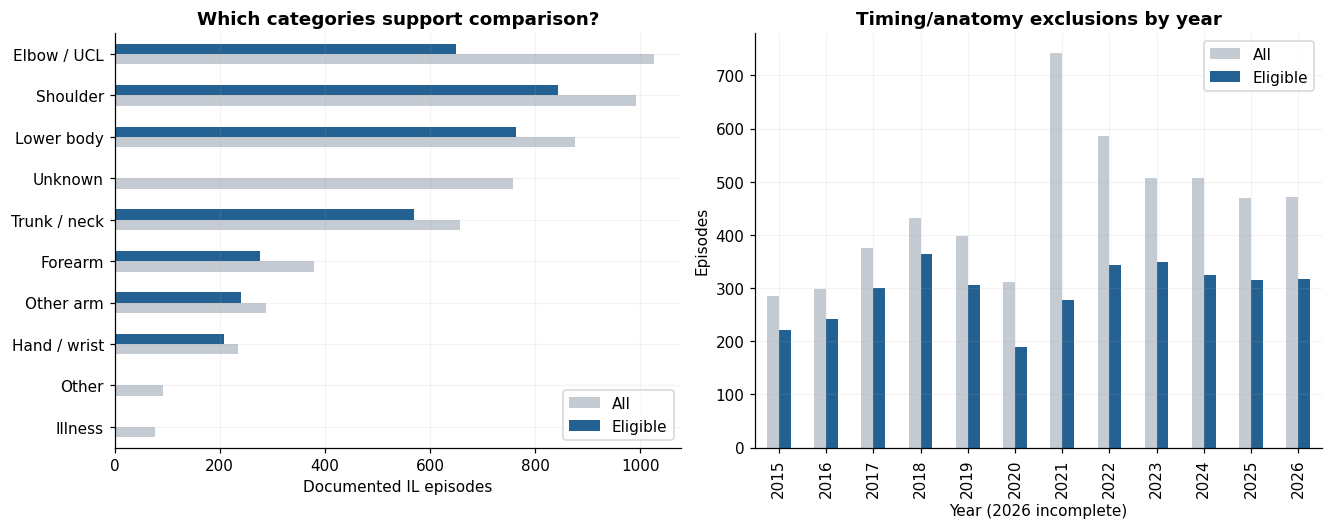

In [3]:
display(read_table('initial_injury_region_counts'))
display(read_table('initial_injury_structure_counts').sort_values('episodes',ascending=False).head(18))
display(read_table('initial_injury_diagnosis_counts').sort_values('episodes',ascending=False))
display(read_table('event_exclusions_overlapping_counts'))
display(events.groupby(['body_group','initial_laterality'],dropna=False).size().rename('episodes').reset_index())
print('Explicit throwing-side eligible events:', events.loc[events.target_eligible,'throwing_arm_injury'].fillna(False).sum())
plots.overview_figure(events); plt.show()

## Historical availability and temporal contract
The prediction timestamp is **after the completed outing**. Existing workload, rolling and pitcher baselines retain the complete prior history actually available; strict prior-date maxima are asserted. Initial label date is the earlier of the recorded injury proxy and reported placement date. Later surgery, activation and duration fields never enter X. Historical descriptions can be revised: reported dates are not verified historical publication timestamps.

Arm angle has a shorter observed history. The long-history model excludes its four fields. No source values are imputed; model-local training-only imputation is documented in notebook 03.

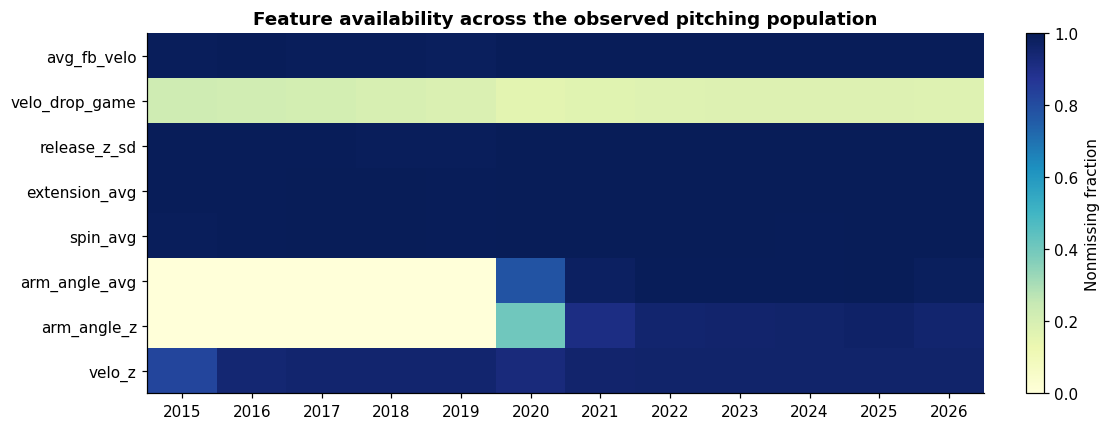

,name,era,train_missing_fraction,rationale
4,velo_drop_game,long_history,0.806619,Late minus early fastball speed in disjoint 20...
20,arm_angle_avg,modern_optional,NaN,Observed arm angle; use only in empirically su...
21,arm_angle_sd,modern_optional,NaN,Arm-angle variability.
22,arm_angle_change_vs_prev_5,modern_optional,NaN,Recent change in arm angle.
23,arm_angle_z,modern_optional,NaN,Arm-angle deviation from pitcher baseline.
62,documented_prior_ucl,long_history,NaN,Documented procedure before this date; absence...
65,release_x_sd_z,long_history,NaN,Existing pitcher-relative release variability ...
66,release_z_sd_z,long_history,NaN,Existing pitcher-relative release variability ...


,check,passed
0,unique pitcher/game keys,True
1,strictly prior rolling/workload dates,True
2,positive events confined to one retained parti...,True
3,current/future outcome fields excluded from X,True
4,database size and mtime unchanged,True
5,all negative labels have observed horizon foll...,True


,outings,observed_30d,positives_30d
partition,,,
descriptive_2026,18427,13363,1775
test,41341,30311,3354
train,132401,89570,9866
validation,41264,29789,3593


**Computed conclusion.** 3,552/5,381 episodes meet the analysis target rules. Initial anatomy is unknown for 14.1% of all episodes. 62 features qualify for the common historical model. Coverage differences and the partially observed 2026 season require era and follow-up restrictions; eligibility does not establish biological onset.

In [4]:
plots.missingness_figure(); plt.show()
display(spec.loc[~spec.selected_for_prediction,['name','era','train_missing_fraction','rationale']])
display(read_table('analysis_validation_checks'))
parts = a.groupby('partition').agg(outings=('row_id','size'), observed_30d=('any_injury_30d','count'), positives_30d=('any_injury_30d','sum'))
display(parts)
unknown = events.analysis_group.eq('Unknown').mean()
conclusion(f"{events.target_eligible.sum():,}/{len(events):,} episodes meet the analysis target rules. Initial anatomy is unknown for {unknown:.1%} of all episodes. {spec.selected_for_prediction.sum()} features qualify for the common historical model. Coverage differences and the partially observed 2026 season require era and follow-up restrictions; eligibility does not establish biological onset.")